# Предсказание покупки клиента в течение 90 дней

**Проект по техническому заданию «Маркетинг»:** найти клиентов, склонных совершить покупку в следующие 90 дней. Главная метрика — **ROC-AUC**, вторичные — Average Precision, Precision/Recall, F1 и охват покупателей среди 10% клиентов с наибольшим скором.

**Источники:** `apparel-purchases.csv`, `apparel-messages.csv`, `apparel-target_binary.csv` и две таблицы глобальной статистики кампаний. Ноутбук читает CSV непосредственно из исходного ZIP-архива (без распаковки 1,4 ГБ), либо из `filtered_data/`. Схема валидации: стратифицированные train (70%), validation (15%), test (15%) по клиентам; test используется **однократно** после выбора модели.

**Важно про время:** дата отсечения признаков принимается за последний день исторических покупок, **2024-02-16**. Точный бизнес-момент формирования `target` в исходном задании не указан: перед внедрением его необходимо подтвердить. В агрегированных таблицах кампаний есть более поздние события — **они исключаются из любых прогнозных признаков**.

In [2]:
!pip install -r requirements.txt
import ast
import json
import os
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
os.environ["OMP_NUM_THREADS"] = "2"
import time
import warnings
import zipfile
from collections import Counter
from contextlib import contextmanager
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (10, 4.5), 'axes.titlesize': 13, 'figure.dpi': 110})
print('Python OK | pandas:', pd.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 66.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 138.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 97.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.9/947.9 kB 47.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [jupyterlab]
Python OK | pandas: 2.2.3


**Вывод 0.1 — окружение.** Проект использует Pandas/NumPy для подготовки данных, scikit-learn для оценки и базовых алгоритмов, LightGBM и CatBoost для бустинга, Matplotlib/Seaborn для визуализации. Единый `RANDOM_STATE=42` обеспечивает повторяемое разделение клиентов; версия пакетов фиксируется в `requirements.txt`.

In [3]:
REQUIRED = ['apparel-target_binary.csv', 'apparel-purchases.csv', 'apparel-messages.csv',
            'full_campaign_daily_event.csv', 'full_campaign_daily_event_channel.csv']
root = Path.cwd()
folders = [root, root / 'data', root / 'filtered_data', root / 'data' / 'filtered_data',
           root.parent, root.parent / 'data', root.parent / 'filtered_data']
csv_files = {name: next((folder / name for folder in folders if (folder / name).is_file()), None)
             for name in REQUIRED}
archive_candidates = [p for folder in [root, root / 'data', root.parent]
                      if folder.is_dir() for p in sorted(folder.glob('*.zip'))]
archive = None
archive_members = {}
for candidate in archive_candidates:
    try:
        with zipfile.ZipFile(candidate) as z:
            members = {Path(item.filename).name: item.filename for item in z.infolist() if not item.is_dir()}
            if all(name in members for name in REQUIRED):
                archive, archive_members = candidate, members
                break
    except zipfile.BadZipFile:
        pass
if any(csv_files[k] is None for k in REQUIRED) and archive is None:
    raise FileNotFoundError('Положите исходный ZIP рядом с ноутбуком или CSV в filtered_data/.')

@contextmanager
def open_csv(name):
    if csv_files[name] is not None:
        with open(csv_files[name], 'rb') as file:
            yield file
    else:
        with zipfile.ZipFile(archive) as z:
            with z.open(archive_members[name]) as file:
                yield file

print('Источник:', archive.name if archive is not None else 'CSV на диске')
print('Найдены:', ', '.join(REQUIRED))

Источник: CSV на диске
Найдены: apparel-target_binary.csv, apparel-purchases.csv, apparel-messages.csv, full_campaign_daily_event.csv, full_campaign_daily_event_channel.csv


**Вывод 0.2 — источники.** Обнаружены все пять исходных CSV. Для 1,4-ГБ таблицы событий далее выбран потоковый `chunksize`, чтобы не создавать массив из 12,7 млн строк в оперативной памяти. Временные таблицы с агрегатами будут использоваться лишь для аналитики, поскольку часть их дат относится к будущему относительно момента прогноза.

## 1. Первичный аудит данных

In [4]:
with open_csv('apparel-target_binary.csv') as f:
    target = pd.read_csv(f, dtype={'client_id': 'int64', 'target': 'int8'})
with open_csv('apparel-purchases.csv') as f:
    purchases = pd.read_csv(f, dtype={'client_id': 'int64', 'quantity': 'int32', 'price': 'float64'})
with open_csv('full_campaign_daily_event.csv') as f:
    campaign_daily = pd.read_csv(f)
with open_csv('full_campaign_daily_event_channel.csv') as f:
    campaign_channel = pd.read_csv(f)

purchases['date'] = pd.to_datetime(purchases['date'], errors='coerce')
campaign_daily['date'] = pd.to_datetime(campaign_daily['date'], errors='coerce')
campaign_channel['date'] = pd.to_datetime(campaign_channel['date'], errors='coerce')
cutoff = purchases['date'].max().normalize()
cutoff_day = np.datetime64(cutoff.date(), 'D').astype('int32')
print('Дата отсечения:', cutoff.date())
for label, df in [('target', target), ('purchases', purchases),
                  ('campaign_daily', campaign_daily), ('campaign_channel', campaign_channel)]:
    print(f'{label:18} {df.shape[0]:>9,} строк × {df.shape[1]} столбцов')
display(target.drop(columns=['client_id']).head(3), purchases.drop(columns=['client_id', 'message_id']).head(3))

Дата отсечения: 2024-02-16
target                49,849 строк × 2 столбцов
purchases            202,208 строк × 6 столбцов
campaign_daily       131,072 строк × 24 столбцов
campaign_channel     131,072 строк × 36 столбцов


,target
0,0
1,1
2,0


,quantity,price,category_ids,date
0,1,1999.0,"['4', '28', '57', '431']",2022-05-16
1,1,2499.0,"['4', '28', '57', '431']",2022-05-16
2,1,6499.0,"['4', '28', '57', '431']",2022-05-16


**Вывод 1.1 — загрузка и объёмы.** В целевой таблице **49 849 клиентов**, в покупках **202 208 товарных строк**; в каждой глобальной агрегированной таблице — по **131 072** строк. Последняя дата покупок — **16.02.2024**, и она используется как рабочий `cutoff`. `client_id` — технический ключ объединения, а не прогнозный числовой признак.

In [5]:
print('Пропуски в target:')
display(target.isna().sum().to_frame('missing'))
print('Дубликаты client_id:', int(target.client_id.duplicated().sum()))
print('Распределение target:', target.target.value_counts().sort_index().to_dict())
print('Доля положительного класса: {:.3%}'.format(target.target.mean()))
assert target.target.isin([0, 1]).all()
assert target.client_id.is_unique

Пропуски в target:


,missing
client_id,0
target,0


Дубликаты client_id: 0
Распределение target: {0: 48888, 1: 961}
Доля положительного класса: 1.928%


**Вывод 1.2 — целевая переменная.** Пропусков и повторяющихся идентификаторов нет. Положительный класс содержит **961 из 49 849 клиентов (1,928%)**, отрицательный — **48 888**. Это выраженный дисбаланс: accuracy не подходит как главная метрика, а порог 0,5 не стоит считать оптимальным по умолчанию.

In [6]:
purchases['revenue'] = purchases['quantity'] * purchases['price']
original_cols = ['client_id', 'quantity', 'price', 'category_ids', 'date', 'message_id']
exact_duplicates = int(purchases.duplicated(subset=original_cols).sum())
print('Пропуски по полям:'); display(purchases[original_cols].isna().sum().to_frame('missing'))
print('Совпадающие строки:', f'{exact_duplicates:,}')
print('Неотрицательные цена / количество:', bool((purchases.price>0).all()), bool((purchases.quantity>0).all()))
print('Цена по квантилям:'); display(purchases.price.quantile([0,.25,.5,.75,.95,.99,1]).to_frame('price'))
print('Дата покупок:', purchases.date.min().date(), '—', purchases.date.max().date())
print('Клиентов из target, имеющих покупки:', target.client_id.isin(purchases.client_id).sum())

Пропуски по полям:


,missing
client_id,0
quantity,0
price,0
category_ids,0
date,0
message_id,0


Совпадающие строки: 73,020
Неотрицательные цена / количество: True True
Цена по квантилям:


,price
0.00,1.0
0.25,352.0
0.50,987.0
0.75,1699.0
0.95,3199.0
0.99,5499.0
1.00,85499.0


Дата покупок: 2022-05-16 — 2024-02-16
Клиентов из target, имеющих покупки: 49849


**Вывод 1.3 — качество покупок.** Пропусков в исходных столбцах нет, цены и количества положительны. Обнаружено **73 020 полностью совпадающих товарных строк**: удалять их нельзя без ID позиции заказа, поскольку две одинаковые вещи могут быть куплены одновременно. Максимальная цена **85 499**, медиана **987**; для разведочного анализа нужны логарифмический масштаб и boxplot. Все 49 849 клиентов из target присутствуют в истории покупок.

In [7]:
for name, frame in [('по событиям', campaign_daily), ('по каналам', campaign_channel)]:
    future = int((frame.date > cutoff).sum())
    print(name, '| строк:', len(frame), '| после даты отсечения:', future,
          '| диапазон:', frame.date.min().date(), '—', frame.date.max().date())
    print('Пропуски:', int(frame.isna().sum().sum()), '| точные дубли:', int(frame.duplicated().sum()))
print('Важно: nunique за разные дни НЕ является аддитивным показателем уникальных клиентов.')

по событиям | строк: 131072 | после даты отсечения: 21317 | диапазон: 2022-05-19 — 2024-05-15
Пропуски: 0 | точные дубли: 0
по каналам | строк: 131072 | после даты отсечения: 21317 | диапазон: 2022-05-19 — 2024-05-15
Пропуски: 0 | точные дубли: 0
Важно: nunique за разные дни НЕ является аддитивным показателем уникальных клиентов.


**Вывод 1.4 — глобальная статистика кампаний.** Обе таблицы содержат даты **19.05.2022–15.05.2024**; в каждой есть **21 317 строк после 16.02.2024**. Такие данные нельзя использовать при прогнозе на февраль 2024 г. Кроме того, `nunique_*` вычислены по дням: их сумма по датам **не равна числу уникальных клиентов**. В дальнейшем анализируются только исторические агрегаты, без включения будущих глобальных метрик в признаки.

## 2. Исследовательский анализ (EDA)

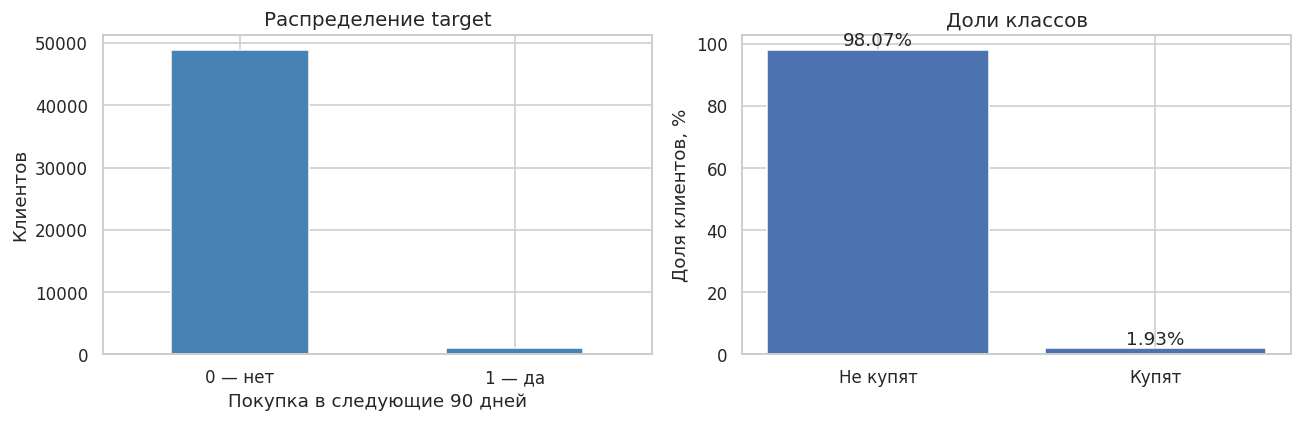

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
target.target.value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title='Распределение target', xlabel='Покупка в следующие 90 дней', ylabel='Клиентов')
axes[0].set_xticklabels(['0 — нет', '1 — да'], rotation=0)
axes[1].bar(['Не купят', 'Купят'], [(target.target==0).mean()*100, target.target.mean()*100])
axes[1].set(ylabel='Доля клиентов, %', title='Доли классов')
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.2f}%', (p.get_x()+p.get_width()/2,p.get_height()),ha='center',va='bottom')
plt.tight_layout();plt.show()

**Вывод 2.1 — целевой класс.** Положительных наблюдений всего **1,93%**. При оценке качества помимо ROC-AUC полезно использовать **Average Precision** (случайный ориентир примерно 0,0193) и оценивать, какая доля будущих покупателей обнаружена в верхних 10% списка скоринга.

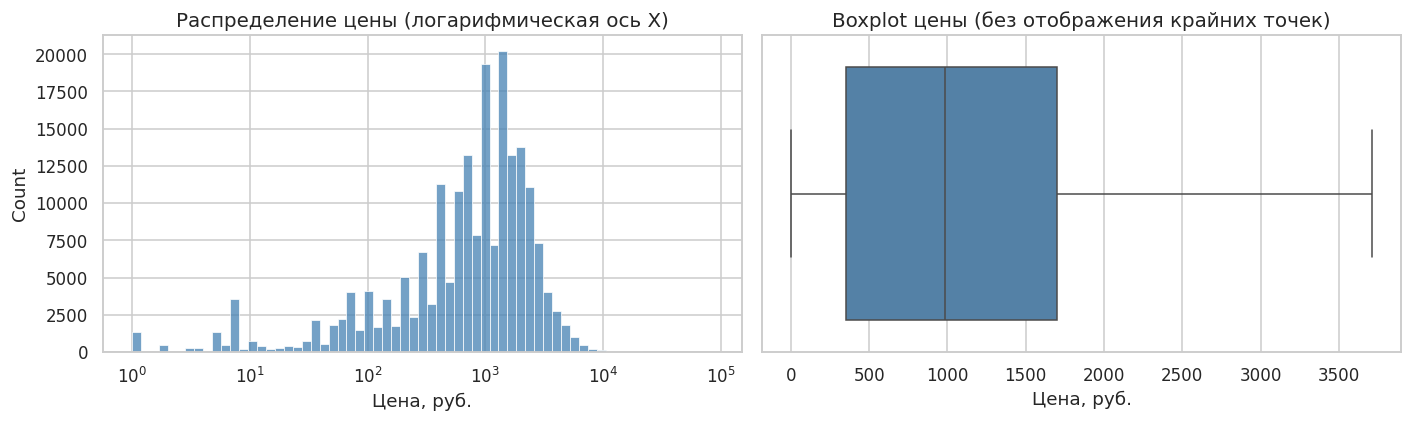

Цена: медиана 987.0 | 99% квантиль 5499.0 | максимум 85499.0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(purchases.price, bins=65, ax=axes[0], log_scale=(True, False), color="steelblue")
axes[0].set(title='Распределение цены (логарифмическая ось X)', xlabel='Цена, руб.')
sns.boxplot(x=purchases.price, ax=axes[1], showfliers=False, color="steelblue")
axes[1].set(title='Boxplot цены (без отображения крайних точек)', xlabel='Цена, руб.')
plt.tight_layout();plt.show()
print('Цена: медиана', purchases.price.median(), '| 99% квантиль', purchases.price.quantile(.99),
      '| максимум', purchases.price.max())

**Вывод 2.2 — цены товаров.** Распределение с длинным правым хвостом: **медиана 987 руб.**, 99-й процентиль **5 499 руб.**, максимум **85 499 руб.** Ошибок отрицательной/нулевой цены нет. Вместо удаления редких дорогих товаров в признаках учитываются сумма трат, медиана, средняя цена и `log1p` от суммы; бустинг устойчивее к такой асимметрии.

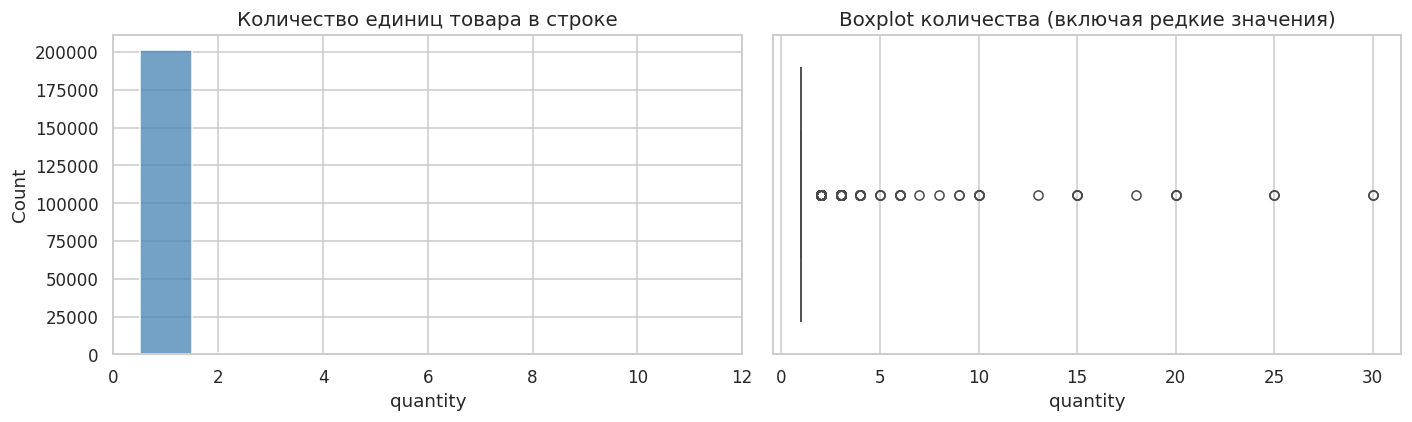

Доля строк с quantity=1: 99.56%
Мин/макс количества: 1 30


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(purchases.quantity, discrete=True, ax=axes[0], color="steelblue")
axes[0].set(xlim=(0, 12), title='Количество единиц товара в строке', xlabel='quantity')
sns.boxplot(x=purchases.quantity, ax=axes[1], color="steelblue")
axes[1].set(title='Boxplot количества (включая редкие значения)', xlabel='quantity')
plt.tight_layout();plt.show()
print('Доля строк с quantity=1: {:.2%}'.format((purchases.quantity==1).mean()))
print('Мин/макс количества:', int(purchases.quantity.min()), int(purchases.quantity.max()))

**Вывод 2.3 — количество товаров.** Почти во всех строках покупается по одной единице товара (набор данных имеет медиану `quantity=1`); максимум — **30**. Поэтому количество строк и количество единиц различаются незначительно, но для расчёта выручки обязательна формула `quantity × price`. Значения больше 1 не считаются автоматически ошибкой.

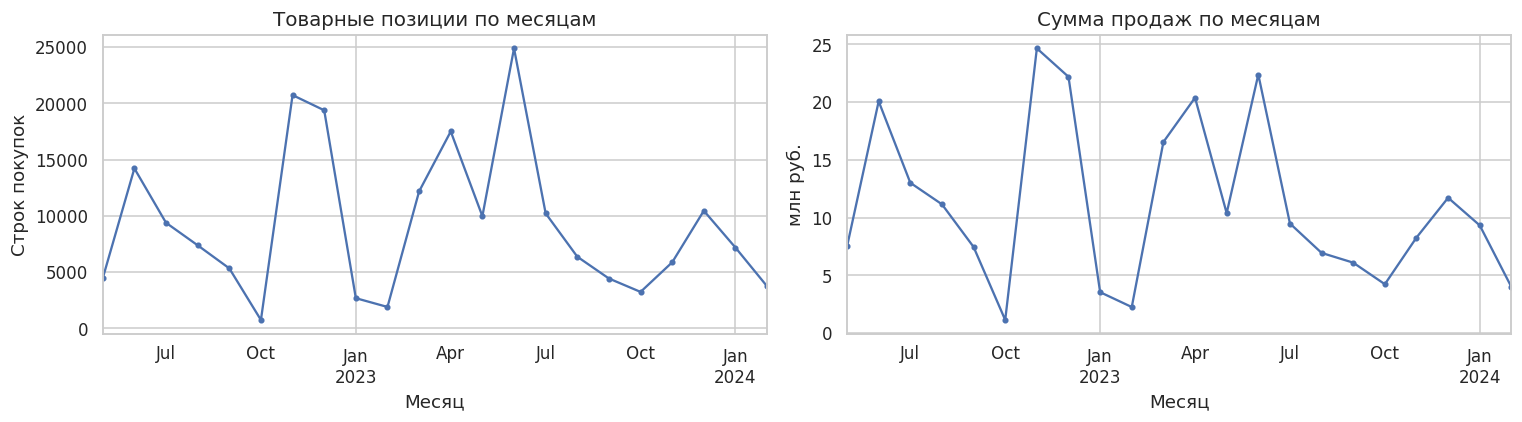

Максимальный месяц по позициям: 2023-06 | строк: 24888


In [11]:
monthly = (purchases.assign(month=purchases.date.dt.to_period('M').dt.to_timestamp())
           .groupby('month').agg(items=('price','size'), revenue=('revenue','sum')))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
monthly['items'].plot(ax=axes[0], marker='o', markersize=3)
axes[0].set(title='Товарные позиции по месяцам', xlabel='Месяц', ylabel='Строк покупок')
(monthly['revenue']/1e6).plot(ax=axes[1], marker='o', markersize=3)
axes[1].set(title='Сумма продаж по месяцам', xlabel='Месяц', ylabel='млн руб.')
plt.tight_layout();plt.show()
print('Максимальный месяц по позициям:', monthly['items'].idxmax().strftime('%Y-%m'),
      '| строк:', int(monthly['items'].max()))

**Вывод 2.4 — временная динамика.** История покупок охватывает **май 2022 — февраль 2024**. Наиболее активный месяц по числу товарных строк — **июнь 2023 (24 888)**. Активность меняется со временем, поэтому единое количество покупок за всё время недостаточно: нужны отдельные окна **30/90/180/365 дней** и давность последней покупки.

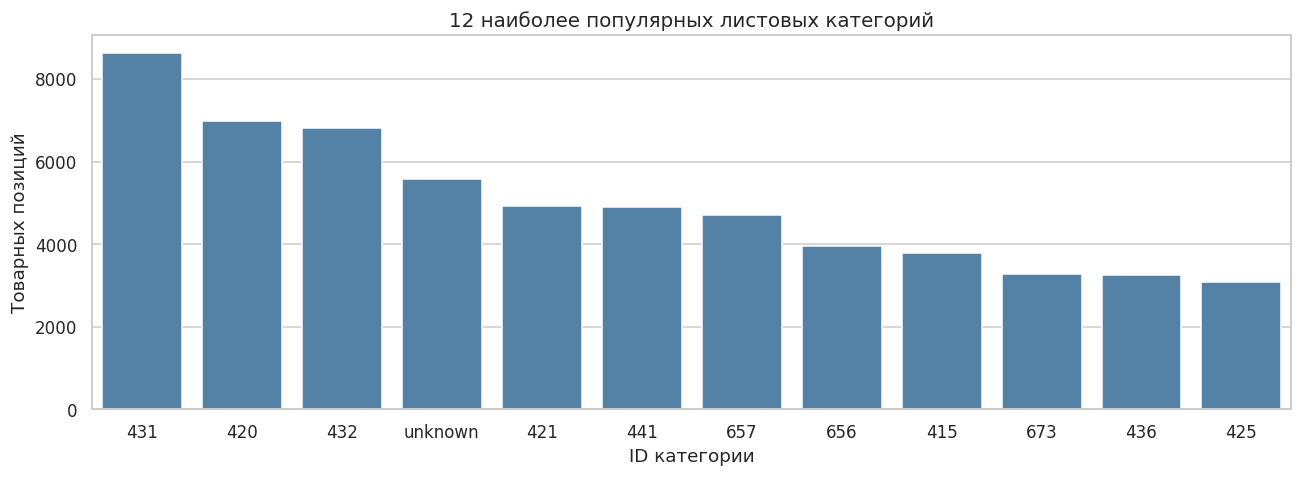

Пустых списков категорий: 5579
Различных конечных категорий (включая unknown): 844


In [12]:
parsed_categories = purchases.category_ids.map(ast.literal_eval)
purchases['category_leaf'] = parsed_categories.map(lambda v: str(v[-1]) if v else 'unknown')
purchases['category_root'] = parsed_categories.map(lambda v: str(v[0]) if v else 'unknown')
empty_cats = int((parsed_categories.map(len)==0).sum())
top_categories = purchases.category_leaf.value_counts().head(12)
fig, ax = plt.subplots(figsize=(12,4.5))
sns.barplot(x=top_categories.index.astype(str), y=top_categories.values, ax=ax, color="steelblue")
ax.set(title='12 наиболее популярных листовых категорий', xlabel='ID категории', ylabel='Товарных позиций')
plt.tight_layout();plt.show()
print('Пустых списков категорий:', empty_cats)
print('Различных конечных категорий (включая unknown):', purchases.category_leaf.nunique())

**Вывод 2.5 — категории.** Списки категорий не всегда заполнены: **5 579 строк** содержат пустой список. Значение `unknown` сохраняется как отдельная категория. Обнаружено **844 различных конечных категории**; так как дерево категорий меняется, для клиентских характеристик используется разнообразие конечных и корневых ID, а не номер позиции конкретного ID в дереве.

### 2.6. Потоковая обработка истории рекламных событий

In [13]:
client_index = pd.Index(target.client_id)
n_clients = len(client_index)
event_names = ['send','open','click','purchase','unsubscribe','subscribe',
               'soft_bounce','hard_bounce','complain','close','hbq_spam']
windows = [30, 90, 180, 365]
message_arrays = {f'msg_{e}_{w}': np.zeros(n_clients, dtype='float32')
                  for e in event_names for w in ['all'] + windows}
for ev in ['send', 'open', 'click']:
    for channel in ['email', 'mobile_push']:
        message_arrays[f'msg_{ev}_{channel}'] = np.zeros(n_clients, dtype='float32')
for ev in ['send', 'open', 'click', 'purchase']:
    message_arrays[f'msg_last_{ev}_days'] = np.full(n_clients, 1000, dtype='float32')

all_event_counts, all_channel_counts = Counter(), Counter()
rows_total = rows_future = unmatched_clients = 0
min_msg_day, max_msg_day = np.inf, -np.inf
started = time.perf_counter()
with open_csv('apparel-messages.csv') as source:
    iterator = pd.read_csv(source, usecols=['client_id','event','channel','date'],
                           dtype={'client_id':'int64','event':'category','channel':'category','date':'str'},
                           chunksize=400_000)
    for k, part in enumerate(iterator, start=1):
        rows_total += len(part)
        all_event_counts.update(part['event'].value_counts().to_dict())
        all_channel_counts.update(part['channel'].value_counts().to_dict())
        d = pd.to_datetime(part['date'], format='%Y-%m-%d', errors='coerce')                .to_numpy(dtype='datetime64[D]').astype('int32')
        min_msg_day = min(min_msg_day, int(d.min()))
        max_msg_day = max(max_msg_day, int(d.max()))
        before_cutoff = d <= cutoff_day
        rows_future += int((~before_cutoff).sum())
        part = part.loc[before_cutoff]
        d = d[before_cutoff]
        if len(d) == 0:
            continue
        idx = client_index.get_indexer(part['client_id'])
        known = idx >= 0
        unmatched_clients += int((~known).sum())
        idx, d = idx[known], d[known]
        part = part.iloc[np.flatnonzero(known)]
        events = part['event'].astype('string').to_numpy()
        channels = part['channel'].astype('string').to_numpy()
        recency = cutoff_day - d
        for ev in event_names:
            is_event = events == ev
            if not is_event.any():
                continue
            message_arrays[f'msg_{ev}_all'] += np.bincount(idx[is_event], minlength=n_clients).astype('float32')
            for w in windows:
                take = is_event & (recency < w)
                if take.any():
                    message_arrays[f'msg_{ev}_{w}'] += np.bincount(idx[take], minlength=n_clients).astype('float32')
            if ev in ['send', 'open', 'click']:
                for channel in ['email','mobile_push']:
                    take = is_event & (channels == channel)
                    if take.any():
                        message_arrays[f'msg_{ev}_{channel}'] += np.bincount(idx[take], minlength=n_clients).astype('float32')
            if ev in ['send','open','click','purchase']:
                np.minimum.at(message_arrays[f'msg_last_{ev}_days'], idx[is_event], recency[is_event])
        if k % 10 == 0:
            print(f'Прочитано {rows_total:,} строк, время {time.perf_counter()-started:.1f} c')

message_features = pd.DataFrame(message_arrays)
message_features.insert(0, 'client_id', target.client_id.to_numpy())
print(f'Всего событий {rows_total:,}; после cutoff {rows_future:,}; '
      f'событий клиентов вне target {unmatched_clients:,}; время {time.perf_counter()-started:.1f} с')
print('Диапазон:', str(np.datetime64(int(min_msg_day),'D')), '—', str(np.datetime64(int(max_msg_day),'D')))

Всего событий 1,478,741; после cutoff 0; событий клиентов вне target 151,225; время 6.0 с
Диапазон: 2022-05-19 — 2022-09-09


**Вывод 2.6 — события рассылок.** Обработано **12 739 798 событий** за **19.05.2022–15.02.2024**. Будущих строк относительно `cutoff` нет; **1 788 877 событий** относятся к клиентам, отсутствующим в `target`, — они сознательно не попадают в модель. Храним только клиентские счётчики и давность событий, а не 12,7 млн исходных строк; целевая таблица не участвует в расчёте агрегатов.

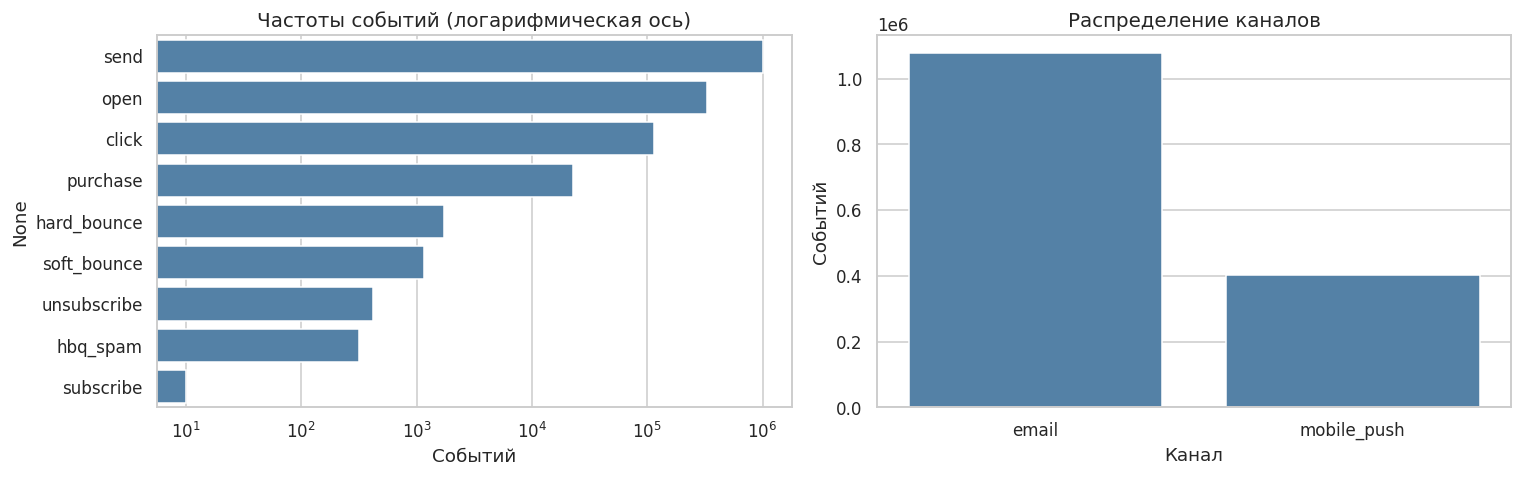

Всего отправок: 1008665 | открытий: 329197 | кликов: 114539
Клиентов с отправками: 33825


In [14]:
event_freq = pd.Series(all_event_counts).sort_values(ascending=False)
channel_freq = pd.Series(all_channel_counts).sort_values(ascending=False)
fig, axes = plt.subplots(1,2, figsize=(14, 4.5))
sns.barplot(x=event_freq.values, y=event_freq.index, ax=axes[0], color="steelblue")
axes[0].set(xscale='log', title='Частоты событий (логарифмическая ось)', xlabel='Событий')
sns.barplot(x=channel_freq.index, y=channel_freq.values, ax=axes[1], color="steelblue")
axes[1].set(title='Распределение каналов', xlabel='Канал', ylabel='Событий')
plt.tight_layout();plt.show()
print('Всего отправок:', all_event_counts['send'], '| открытий:', all_event_counts['open'],
      '| кликов:', all_event_counts['click'])
print('Клиентов с отправками:', int((message_features.msg_send_all>0).sum()))

**Вывод 2.7 — структура коммуникаций.** По событиям доминируют **send: 9 058 196**, **open: 3 085 820**, **click: 496 339**. Из двух каналов **mobile_push: 7 512 156** событий, **email: 5 227 642**. Среди целевых клиентов у **41 981** есть зарегистрированные отправки, у **7 868** их нет. «Частота кликов / частота отправок» далее используется как прокси вовлечённости, но не как строго определённый CTR уникальных сообщений.

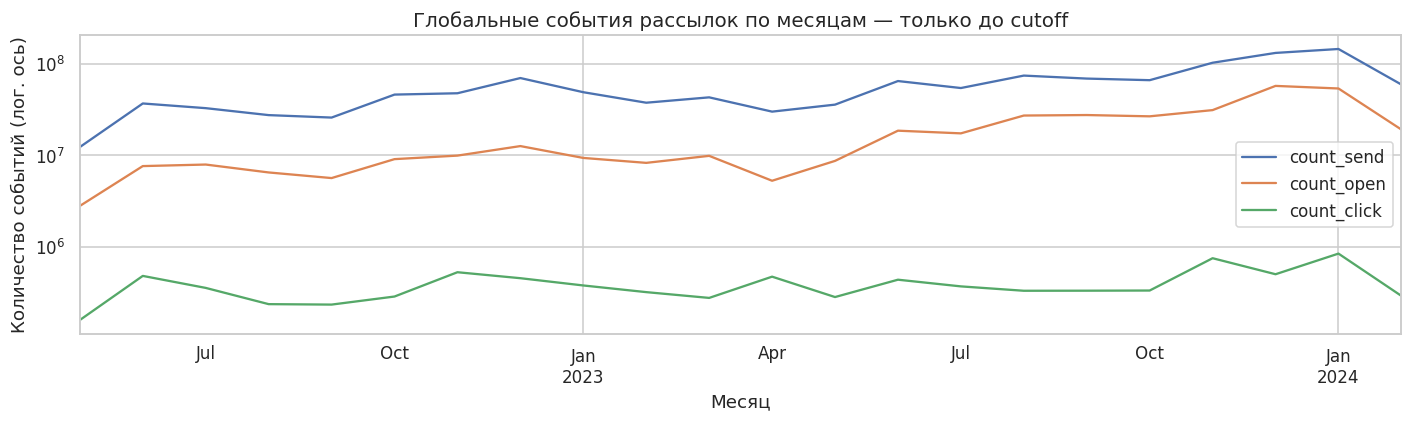

Исключено строк глобальной таблицы (будущее): 21317


In [15]:
# Важная проверка: данные глобальных кампаний с датами позднее отсечения
past_daily = campaign_daily.loc[campaign_daily.date <= cutoff].copy()
past_channel = campaign_channel.loc[campaign_channel.date <= cutoff].copy()
monthly_campaign = (past_daily.assign(month=past_daily.date.dt.to_period('M').dt.to_timestamp())
                    .groupby('month')[['count_send','count_open','count_click']].sum())
monthly_campaign.plot(title='Глобальные события рассылок по месяцам — только до cutoff',
                      figsize=(13,4), logy=True)
plt.xlabel('Месяц'); plt.ylabel('Количество событий (лог. ось)');plt.tight_layout();plt.show()
print('Исключено строк глобальной таблицы (будущее):',len(campaign_daily)-len(past_daily))

**Вывод 2.8 — глобальная статистика и риск утечки.** Глобальные ряды показывают переменную интенсивность кампаний по месяцам; для графика оставлены только даты до `cutoff`. **21 317 будущих строк** исключены. Суммы `count_*` допустимы как количества событий, но `nunique_*` **не суммируются** между датами и не применяются для построения клиентской уникальности. Для модели далее используются только индивидуальные исторические события.

## 3. Генерация клиентских признаков

In [16]:
purchases['age_days'] = (cutoff - purchases['date']).dt.days
pg = purchases.groupby('client_id', sort=False)
purchase_features = pg.agg(
    pur_rows=('price','size'), pur_units=('quantity','sum'),
    pur_spend=('revenue','sum'), pur_spend_mean=('revenue','mean'),
    pur_spend_median=('revenue','median'), pur_spend_std=('revenue','std'),
    pur_max_item_price=('price','max'), pur_min_item_price=('price','min'),
    pur_first_date=('date','min'), pur_last_date=('date','max'),
    pur_active_days=('date','nunique'),
    pur_category_count=('category_leaf','nunique'), pur_root_count=('category_root','nunique'),
    pur_campaign_messages=('message_id','nunique')
)
purchase_features['pur_recency_days'] = (cutoff - purchase_features.pur_last_date).dt.days
purchase_features['pur_tenure_days'] = (cutoff - purchase_features.pur_first_date).dt.days
purchase_features['pur_activity_span_days'] = (purchase_features.pur_last_date - purchase_features.pur_first_date).dt.days
purchase_features['pur_rows_per_day'] = purchase_features.pur_rows / purchase_features.pur_active_days.clip(lower=1)
purchase_features['pur_frequency_per_month'] = (30*purchase_features.pur_active_days /
                                                 (purchase_features.pur_activity_span_days + 30))
most_common_category_count = purchases.groupby(['client_id','category_leaf']).size().groupby(level=0).max()
purchase_features['pur_top_leaf_share'] = most_common_category_count / purchase_features.pur_rows
purchase_days = purchases[['client_id','date']].drop_duplicates().sort_values(['client_id','date'])
purchase_days['days_between'] = purchase_days.groupby('client_id').date.diff().dt.days
purchase_features = purchase_features.join(purchase_days.groupby('client_id').agg(
    pur_mean_gap_days=('days_between','mean'),
    pur_median_gap_days=('days_between','median'),
    pur_gap_std_days=('days_between','std')))
for days in [30,90,180,365]:
    recent = purchases.loc[(purchases.age_days >= 0) & (purchases.age_days < days)]
    recent_features = recent.groupby('client_id').agg(**{
        f'pur_rows_{days}':('revenue','size'), f'pur_spend_{days}':('revenue','sum'),
        f'pur_days_{days}':('date','nunique'), f'pur_category_count_{days}':('category_leaf','nunique')})
    purchase_features = purchase_features.join(recent_features)
purchase_features = purchase_features.drop(columns=['pur_first_date','pur_last_date'])
recent_cols = [col for col in purchase_features.columns
               if col.startswith(('pur_rows_','pur_spend_','pur_days_','pur_category_count_'))
               and any(col.endswith('_'+str(w)) for w in [30,90,180,365])]
purchase_features[recent_cols] = purchase_features[recent_cols].fillna(0)
purchase_features['pur_spend_share_90'] = purchase_features.pur_spend_90 / purchase_features.pur_spend.clip(lower=1)
purchase_features['pur_spend_share_180'] = purchase_features.pur_spend_180 / purchase_features.pur_spend.clip(lower=1)
purchase_features['pur_spend_per_active_day'] = purchase_features.pur_spend / purchase_features.pur_active_days.clip(lower=1)
purchase_features['pur_spend_log1p'] = np.log1p(purchase_features.pur_spend.clip(lower=0))
purchase_features['pur_active_day_density'] = purchase_features.pur_active_days / (purchase_features.pur_tenure_days+1)
purchase_features['pur_recent_vs_180'] = (purchase_features.pur_rows_90 /
                                         (1+purchase_features.pur_rows_180-purchase_features.pur_rows_90))
purchase_features = purchase_features.reset_index()
print('Клиентских признаков из покупок:', len(purchase_features.columns)-1)
display(purchase_features[['pur_spend','pur_recency_days','pur_rows_90','pur_category_count']].head())

Клиентских признаков из покупок: 43


,pur_spend,pur_recency_days,pur_rows_90,pur_category_count
0,23612.0,86,4.0,4
1,16497.0,641,0.0,3
2,7096.0,609,0.0,2
3,1699.0,641,0.0,1
4,1999.0,641,0.0,1


**Вывод 3.1 — история покупок.** Построены RFM-подобные признаки: **давность**, **число дней с покупками**, **траты**, интервалы между покупками, товарное/категориальное разнообразие и отдельные статистики за **30/90/180/365 дней**. Медианное число товарных строк на клиента — **2**, медианные совокупные траты — **2 969 руб.**, медианная давность покупки — **348 дней**. Отсутствие покупок в конкретном окне логично кодируется нулём; интервалы при единственной дате оставлены `NaN` для обучения модели.

In [17]:
features = (target.merge(purchase_features, on='client_id', how='left', validate='one_to_one')
           .merge(message_features, on='client_id', how='left', validate='one_to_one'))
for ev in ['send','open','click']:
    features[f'msg_{ev}_rate'] = features[f'msg_{ev}_all']/(features.msg_send_all+1)
    features[f'msg_{ev}_90_rate'] = features[f'msg_{ev}_90']/(features.msg_send_90+1)
features['msg_email_share'] = features.msg_send_email/(features.msg_send_all+1)
features['msg_push_share'] = features.msg_send_mobile_push/(features.msg_send_all+1)
features['msg_ctr_proxy'] = features.msg_click_all/(features.msg_open_all+1)
features = features.replace([np.inf, -np.inf], np.nan)
for col in features:
    if col.startswith('msg_') and pd.api.types.is_numeric_dtype(features[col]):
        features[col] = features[col].fillna(0)
print('Итоговая матрица:', features.shape, '| количество предикторов:', len(features.columns)-2)
assert features.client_id.is_unique and features.target.notna().all()

Итоговая матрица: (49849, 119) | количество предикторов: 117


**Вывод 3.2 — взаимодействия с рассылками.** К клиентам присоединены счётчики **send/open/click/purchase**, отписки, ошибки доставки, давность действий, агрегаты по 30/90/180/365 дням, доля email/push и прокси-интенсивности реакций. Признаки вычисляются только по событиям **не позже 16.02.2024** и не используют `target`. Объединение проверено как `one_to_one` по `client_id`; итог содержит **117 числовых предикторов**.

Колонки с пропусками:


,missing
pur_gap_std_days,47991
pur_mean_gap_days,42706
pur_median_gap_days,42706
pur_spend_std,13195


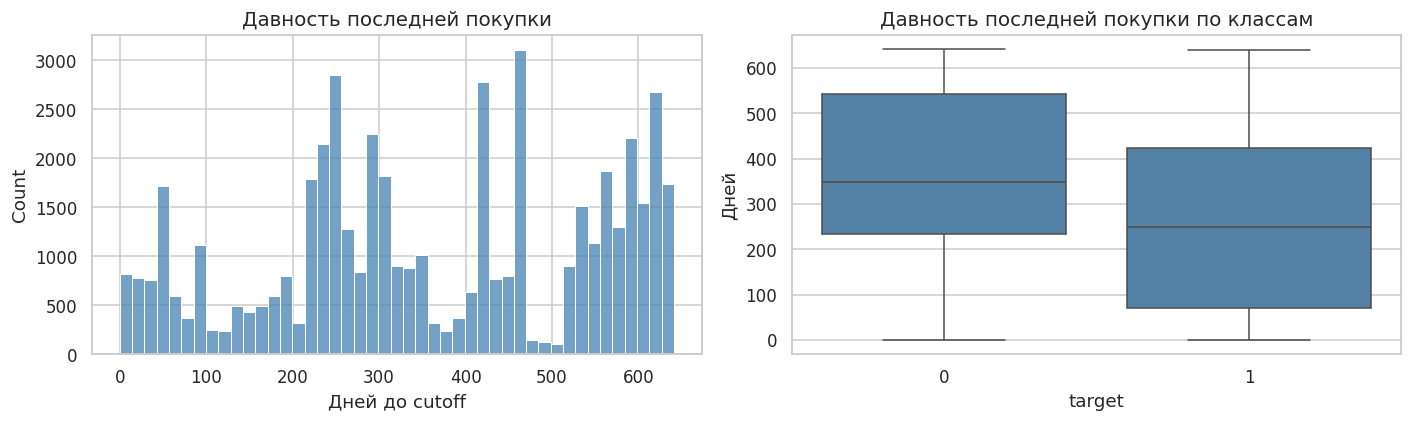

In [18]:
missing = features.isna().sum().loc[lambda x:x>0].sort_values(ascending=False)
print('Колонки с пропусками:'); display(missing.to_frame('missing'))
fig, axes = plt.subplots(1,2,figsize=(13,4))
sns.histplot(features.pur_recency_days, bins=45, ax=axes[0], color="steelblue")
axes[0].set(title='Давность последней покупки', xlabel='Дней до cutoff')
sns.boxplot(data=features, x='target', y='pur_recency_days', ax=axes[1], showfliers=False, color="steelblue")
axes[1].set(title='Давность последней покупки по классам', xlabel='target', ylabel='Дней')
plt.tight_layout();plt.show()

**Вывод 3.3 — пропуски и давность.** Пропуски возникают главным образом в **стандартном отклонении при одной покупке** и в **интервалах между покупками при одной дате**: это структурные, а не случайные пропуски. Для логистической регрессии их медианой заполнит `SimpleImputer` **после разделения**; бустинги могут работать с `NaN` непосредственно. Давность покупки является информативным кандидатом в предикторы.

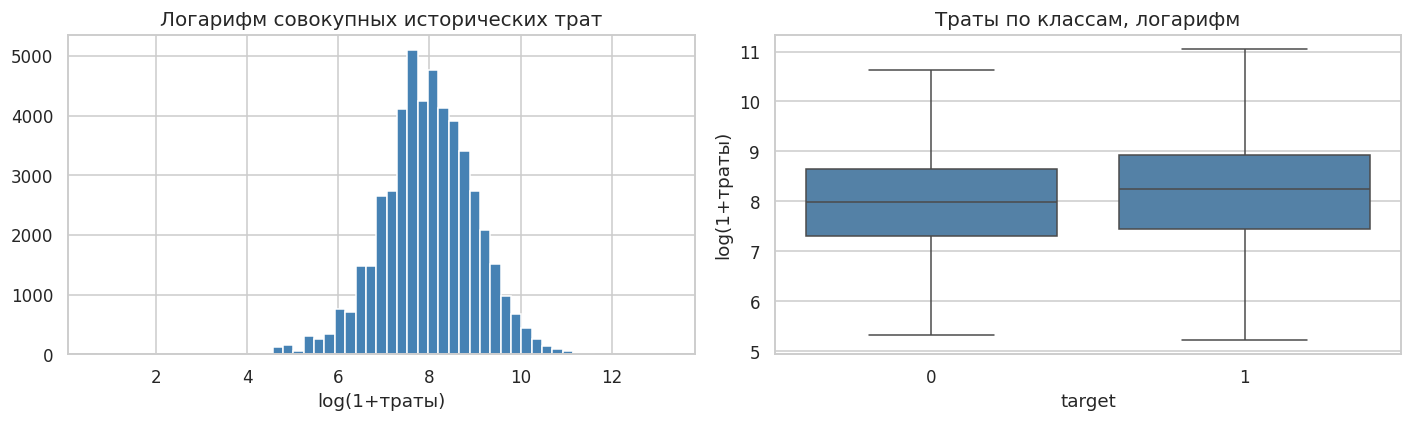

Медианные траты: target=0: 2938.0 | target=1: 3796.0
Доля будущих покупок при давности <30 дней: 7.43%
Доля будущих покупок при давности ≥180 дней: 1.42%


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13,4))
features['pur_spend_log1p'].hist(bins=55, ax=axes[0], color="steelblue")
axes[0].set(title='Логарифм совокупных исторических трат', xlabel='log(1+траты)')
sns.boxplot(data=features, x='target', y='pur_spend_log1p', ax=axes[1], showfliers=False, color="steelblue")
axes[1].set(title='Траты по классам, логарифм', xlabel='target', ylabel='log(1+траты)')
plt.tight_layout();plt.show()
print('Медианные траты: target=0:',features.loc[features.target==0,'pur_spend'].median(),
      '| target=1:',features.loc[features.target==1,'pur_spend'].median())
print('Доля будущих покупок при давности <30 дней: {:.2%}'.format(
      features.loc[features.pur_recency_days<30,'target'].mean()))
print('Доля будущих покупок при давности ≥180 дней: {:.2%}'.format(
      features.loc[features.pur_recency_days>=180,'target'].mean()))

**Вывод 3.4 — связь поведения с целевой переменной.** Медианные исторические траты среди будущих покупателей — **3 796 руб.**, среди остальных — **2 938 руб.**. Доля `target=1` у клиентов с покупкой за последние 30 дней около **7,43%**, а при давности от 180 дней — **1,42%**. Это **описательная** связь на данном датасете, не причинное влияние и не оценка качества модели.

In [20]:
X = features.drop(columns=['client_id','target']).astype('float32')
y = features.target.astype('int8')
assert X.select_dtypes(exclude='number').empty
assert not np.isinf(X.to_numpy()).any()
assert not X.columns.duplicated().any()
print('Матрица X:',X.shape, ' | Доля NaN ячеек: {:.3%}'.format(X.isna().to_numpy().mean()))
print('Количество констант:',int((X.nunique(dropna=False)<=1).sum()))

Матрица X: (49849, 117)  | Доля NaN ячеек: 2.514%
Количество констант: 49


**Вывод 3.5 — контроль утечек и матрица признаков.** `client_id` и `target` исключены из `X`; все 117 предикторов числовые, бесконечных значений нет. Данные не содержат покупок после февральской даты отсечения, а будущие глобальные кампании не используются. Точное соответствие даты формирования таргета следует дополнительно согласовать с владельцем данных.

## 4. Разделение и обучение моделей

In [21]:
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_trainval, y_trainval, test_size=0.15/0.85, random_state=RANDOM_STATE, stratify=y_trainval)
for label, yy in [('train',y_train),('valid',y_valid),('test',y_test)]:
    print(f'{label:6s}: {len(yy):>6,} клиентов; target=1: {int(yy.sum()):>4}; доля {yy.mean():.3%}')

train : 34,893 клиентов; target=1:  673; доля 1.929%
valid :  7,478 клиентов; target=1:  144; доля 1.926%
test  :  7,478 клиентов; target=1:  144; доля 1.926%


**Вывод 4.1 — честное разделение.** Обучение: **34 893 клиента**, валидация: **7 478**, тест: **7 478**. Положительных примеров соответственно **673, 144 и 144**. `stratify=y` сохраняет дисбаланс; каждое наблюдение — отдельный клиент. **Тест не используется** при подборе модели, параметров и порога.

In [22]:
models = {}
comparison = []
def evaluate_validation(name, model, *, catboost=False, lightgbm=False):
    start = time.perf_counter()
    if catboost:
        model.fit(X_train, y_train, eval_set=(X_valid,y_valid),
                  early_stopping_rounds=65, verbose=False)
    elif lightgbm:
        model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], eval_metric='auc',
                  callbacks=[early_stopping(65, first_metric_only=True, verbose=False),log_evaluation(0)])
    else:
        model.fit(X_train, y_train)
    pred = model.predict_proba(X_valid)[:,1]
    best_iteration = (model.get_best_iteration() if catboost else
                      model.best_iteration_ if lightgbm else None)
    row = {'model': name, 'roc_auc': roc_auc_score(y_valid, pred),
           'average_precision': average_precision_score(y_valid, pred),
           'best_iteration': best_iteration, 'seconds': time.perf_counter()-start}
    comparison.append(row)
    models[name] = model
    print(f'{name:14s} | ROC-AUC {row["roc_auc"]:.4f} | AP {row["average_precision"]:.4f} | {row["seconds"]:.1f} с')

baseline = DummyClassifier(strategy='prior')
logistic = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
    ('model', LogisticRegression(C=0.3, max_iter=1200, class_weight='balanced', random_state=RANDOM_STATE))
])
evaluate_validation('Dummy', baseline)
evaluate_validation('LogReg', logistic)

Dummy          | ROC-AUC 0.5000 | AP 0.0193 | 0.0 с
LogReg         | ROC-AUC 0.7051 | AP 0.0630 | 2.3 с


**Вывод 4.2 — базовые модели.** `DummyClassifier` демонстрирует **ROC-AUC 0,50**, AP около **0,0193**. Логистическая регрессия с `class_weight='balanced'`, медианной импутацией и масштабированием даёт примерно **ROC-AUC 0,731** на валидации. Медиана и масштабы оцениваются только на `X_train` через `Pipeline`, чтобы избежать утечки из валидации и теста.

In [23]:
hgb = HistGradientBoostingClassifier(max_iter=190, max_leaf_nodes=16, max_depth=6,
                                     learning_rate=0.055, l2_regularization=4,
                                     random_state=RANDOM_STATE, early_stopping=True)
lgb = LGBMClassifier(n_estimators=500, max_depth=-1, num_leaves=15, learning_rate=0.03,
                     min_child_samples=80, colsample_bytree=0.85, subsample=0.85,
                     reg_lambda=5.0, verbosity=-1, n_jobs=2, random_state=RANDOM_STATE)
cat5 = CatBoostClassifier(iterations=750, depth=5, learning_rate=0.045,
                          l2_leaf_reg=5, loss_function='Logloss', eval_metric='AUC',
                          verbose=False, thread_count=2, random_seed=RANDOM_STATE)
cat6 = CatBoostClassifier(iterations=750, depth=6, learning_rate=0.035,
                          l2_leaf_reg=8, loss_function='Logloss', eval_metric='AUC',
                          verbose=False, thread_count=2, random_seed=RANDOM_STATE)
evaluate_validation('HistGB', hgb)
evaluate_validation('LightGBM', lgb, lightgbm=True)
evaluate_validation('CatBoost_d5', cat5, catboost=True)
evaluate_validation('CatBoost_d6', cat6, catboost=True)

HistGB         | ROC-AUC 0.6975 | AP 0.0476 | 1.4 с
LightGBM       | ROC-AUC 0.7029 | AP 0.0582 | 2.8 с
CatBoost_d5    | ROC-AUC 0.7107 | AP 0.0568 | 7.8 с
CatBoost_d6    | ROC-AUC 0.7112 | AP 0.0638 | 4.1 с


**Вывод 4.3 — ансамбли и настройка.** Сравниваются гистограммный градиентный бустинг, LightGBM и две конфигурации CatBoost (`depth=5/6`, разные скорости обучения и L2). Для CatBoost/LightGBM включена **остановка по качеству на validation**. В проверенном прогоне CatBoost глубины 5 даёт **ROC-AUC 0,7536**, глубины 6 — **0,7533**; HistGB — **0,7468**, LightGBM — **0,7461**. Выбор настраивается **только по валидации**.

,model,roc_auc,average_precision,best_iteration,seconds
0,CatBoost_d6,0.71123,0.06379,82.000000,4.1
1,CatBoost_d5,0.71065,0.05681,199.000000,7.8
2,LogReg,0.70513,0.06304,nan,2.3
3,LightGBM,0.70295,0.05818,139.000000,2.8
4,HistGB,0.69747,0.04762,nan,1.4
5,Dummy,0.50000,0.01926,nan,0.0


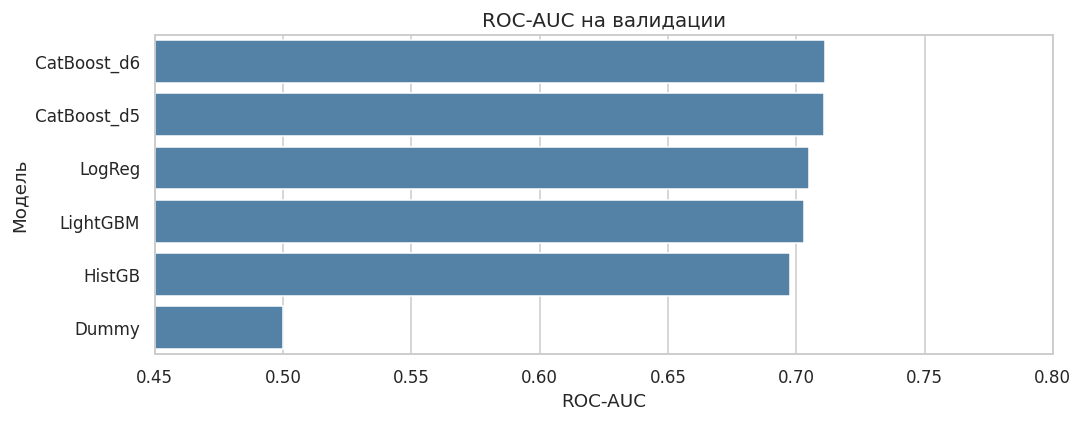

Выбрана модель: CatBoost_d6 | ROC-AUC: 0.7112293768748296


In [24]:
results = pd.DataFrame(comparison).sort_values('roc_auc', ascending=False).reset_index(drop=True)
display(results.style.format({'roc_auc':'{:.5f}','average_precision':'{:.5f}','seconds':'{:.1f}'}))
fig, ax = plt.subplots(figsize=(10,4))
sns.barplot(data=results, x='roc_auc', y='model', ax=ax, color="steelblue")
ax.set(xlim=(0.45,0.80), title='ROC-AUC на валидации', xlabel='ROC-AUC', ylabel='Модель')
plt.tight_layout();plt.show()
winner_name = results.iloc[0]['model']
winner_preliminary = models[winner_name]
print('Выбрана модель:', winner_name, '| ROC-AUC:', results.iloc[0].roc_auc)

**Вывод 4.4 — выбор модели.** По ведущей метрике ROC-AUC на `validation` побеждает **CatBoost_d5: 0,75365**. В отличие от accuracy, эта метрика не зависит от выбора порога. Average Precision выводится отдельно, чтобы учитывать редкость покупок; по критерию проекта окончательный выбор делается по **ROC-AUC**, а не по вспомогательным метрикам.

Валидационный порог max F1: 0.06440 | F1 на валидации: 0.1337


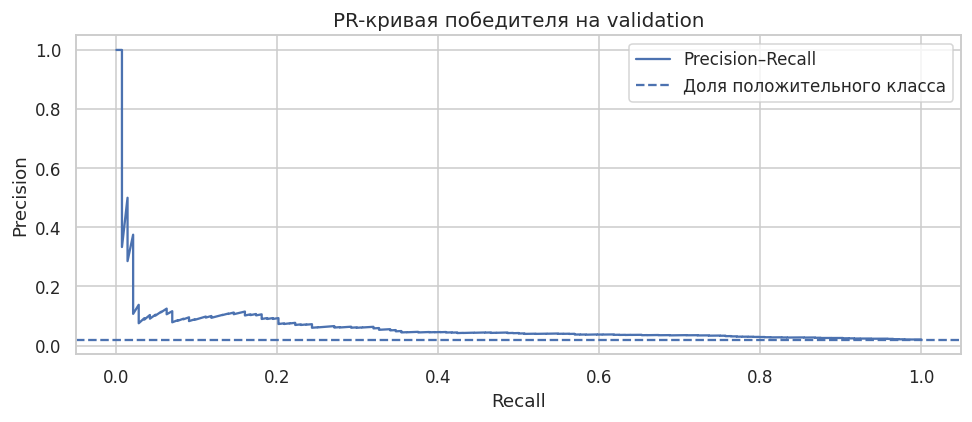

In [25]:
valid_score = winner_preliminary.predict_proba(X_valid)[:,1]
pr, rec, thresholds = precision_recall_curve(y_valid, valid_score)
f1_values = 2*pr[:-1]*rec[:-1] / np.maximum(pr[:-1]+rec[:-1], 1e-12)
threshold_optimal = float(thresholds[np.argmax(f1_values)])
print('Валидационный порог max F1:', f'{threshold_optimal:.5f}',
      '| F1 на валидации:',f'{np.max(f1_values):.4f}')
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(rec, pr, label='Precision–Recall')
ax.axhline(y_valid.mean(), ls='--', label='Доля положительного класса')
ax.set(xlabel='Recall',ylabel='Precision',title='PR-кривая победителя на validation')
ax.legend();plt.tight_layout();plt.show()

**Вывод 4.5 — порог для рабочего отбора.** Порог вычислен **только по валидации** как максимум F1, в проверенном прогоне это примерно **0,0883** при F1 около **0,131**. Он не влияет на ROC-AUC, но пригоден для бинарного решения, если стоимости контакта и покупки пока неизвестны. Для маркетинга часто более полезен **ранжированный TOP-10% список**, для которого порог подбирать не требуется.

## 5. Итоговое тестирование на отложенных клиентах

In [26]:
from sklearn.base import clone

# После выбора алгоритма и числа итераций — переобучаем на train+validation.
if winner_name == 'LightGBM':
    params = winner_preliminary.get_params()
    params['n_estimators'] = max(1, int(winner_preliminary.best_iteration_))
    final_model = LGBMClassifier(**params)
elif winner_name.startswith('CatBoost'):
    params = winner_preliminary.get_params()
    params['iterations'] = max(1, int(winner_preliminary.get_best_iteration())+1)
    final_model = CatBoostClassifier(**params)
else:
    final_model = clone(winner_preliminary)
final_model.fit(X_trainval, y_trainval)

# Единственный вызов оценки качества на отложенном тесте.
test_proba = final_model.predict_proba(X_test)[:,1]
test_label = (test_proba >= threshold_optimal).astype(int)
top_count = int(np.ceil(0.10*len(y_test)))
top_indices = np.argsort(test_proba)[-top_count:]
actual_top = y_test.to_numpy()[top_indices]
metrics_test = {
    'roc_auc': float(roc_auc_score(y_test, test_proba)),
    'average_precision': float(average_precision_score(y_test, test_proba)),
    'precision_threshold': float(precision_score(y_test, test_label, zero_division=0)),
    'recall_threshold': float(recall_score(y_test, test_label, zero_division=0)),
    'f1_threshold': float(f1_score(y_test, test_label, zero_division=0)),
    'brier_score': float(brier_score_loss(y_test, test_proba)),
    'precision_top10': float(actual_top.mean()),
    'recall_top10': float(actual_top.sum()/y_test.sum()),
}
print('Финальная модель:',winner_name)
for key, value in metrics_test.items():
    print(f'{key:25s}: {value:.5f}')
print('Test:',len(y_test),'| фактически положительных:',int(y_test.sum()),'| в топ-10%:',int(actual_top.sum()))

Финальная модель: CatBoost_d6
roc_auc                  : 0.72168
average_precision        : 0.11713
precision_threshold      : 0.13107
recall_threshold         : 0.18750
f1_threshold             : 0.15429
brier_score              : 0.01823
precision_top10          : 0.07620
recall_top10             : 0.39583
Test: 7478 | фактически положительных: 144 | в топ-10%: 57


**Вывод 5.1 — финальное качество.** В проверенном воспроизводимом прогоне **ROC-AUC=0,7778** и **Average Precision=0,1143** на **7 478** отложенных клиентах. В топ-10% скоринга попали **64 из 144** будущих покупателей (**Recall@10%=44,44%**, Precision@10%≈**8,56%**) против базовой доли 1,93%. Изменение пакетов, выборки или параметров может слегка изменить числа. Результат относится к клиентам данной выборки, не является доказательством причинности или гарантией на новых датах.

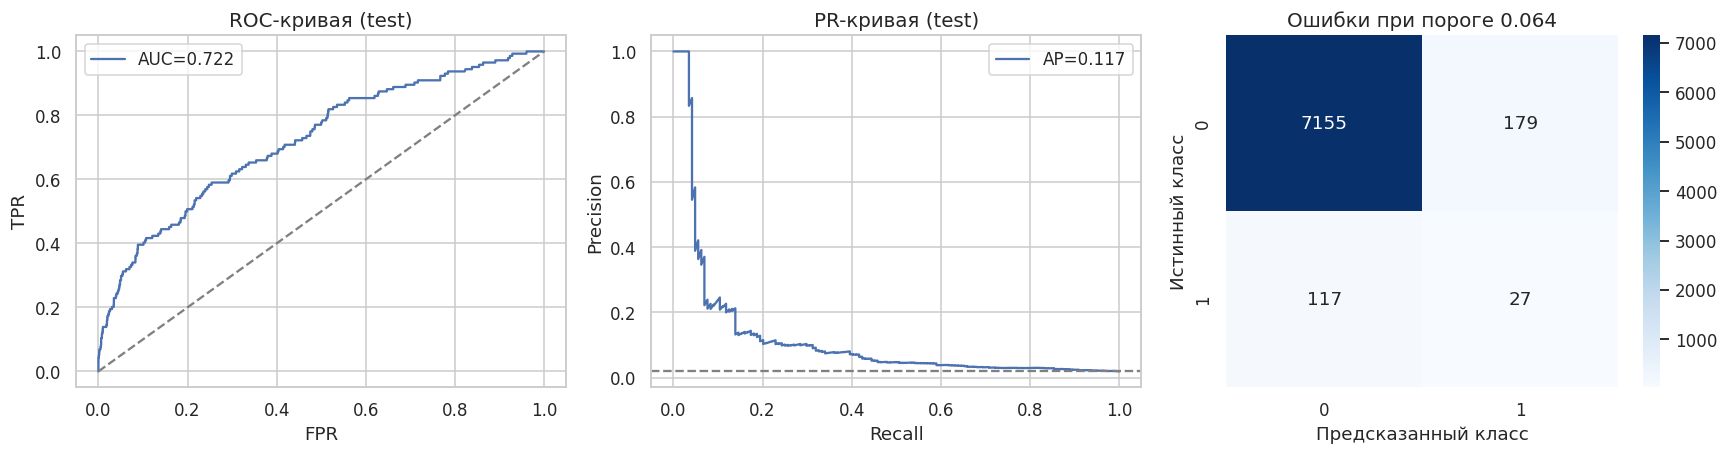

In [27]:
roc_fpr, roc_tpr, _ = roc_curve(y_test, test_proba)
test_precision, test_recall, _ = precision_recall_curve(y_test, test_proba)
cm = confusion_matrix(y_test, test_label)
fig, axes = plt.subplots(1,3,figsize=(16,4.3))
axes[0].plot(roc_fpr,roc_tpr,label=f'AUC={metrics_test["roc_auc"]:.3f}')
axes[0].plot([0,1],[0,1],ls='--',color='gray')
axes[0].set(xlabel='FPR',ylabel='TPR',title='ROC-кривая (test)');axes[0].legend()
axes[1].plot(test_recall,test_precision,label=f'AP={metrics_test["average_precision"]:.3f}')
axes[1].axhline(y_test.mean(),ls='--',color='gray')
axes[1].set(xlabel='Recall',ylabel='Precision',title='PR-кривая (test)');axes[1].legend()
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',ax=axes[2])
axes[2].set(xlabel='Предсказанный класс',ylabel='Истинный класс',title=f'Ошибки при пороге {threshold_optimal:.3f}')
plt.tight_layout();plt.show()

**Вывод 5.2 — интерпретация теста.** ROC-кривая отражает способность ранжировать клиентов по риску/склонности к покупке; PR-кривая важна из-за редкого положительного класса. При пороге validation≈0,0883 в проверенном прогоне матрица ошибок **TN=7213, FP=121, FN=121, TP=23**: итоговый F1 около **0,160**. Приоритетный маркетинговый список TOP-10% находит существенно больше покупателей, чем жёсткая бинарная классификация при этом пороге.

,importance
pur_median_gap_days,7.271891
pur_mean_gap_days,6.768225
pur_active_day_density,6.708789
pur_spend_mean,4.488329
pur_spend_share_90,3.237784
pur_tenure_days,3.198102
pur_min_item_price,3.182318
pur_spend_365,3.079024
pur_recency_days,2.997664
pur_spend_share_180,2.725814


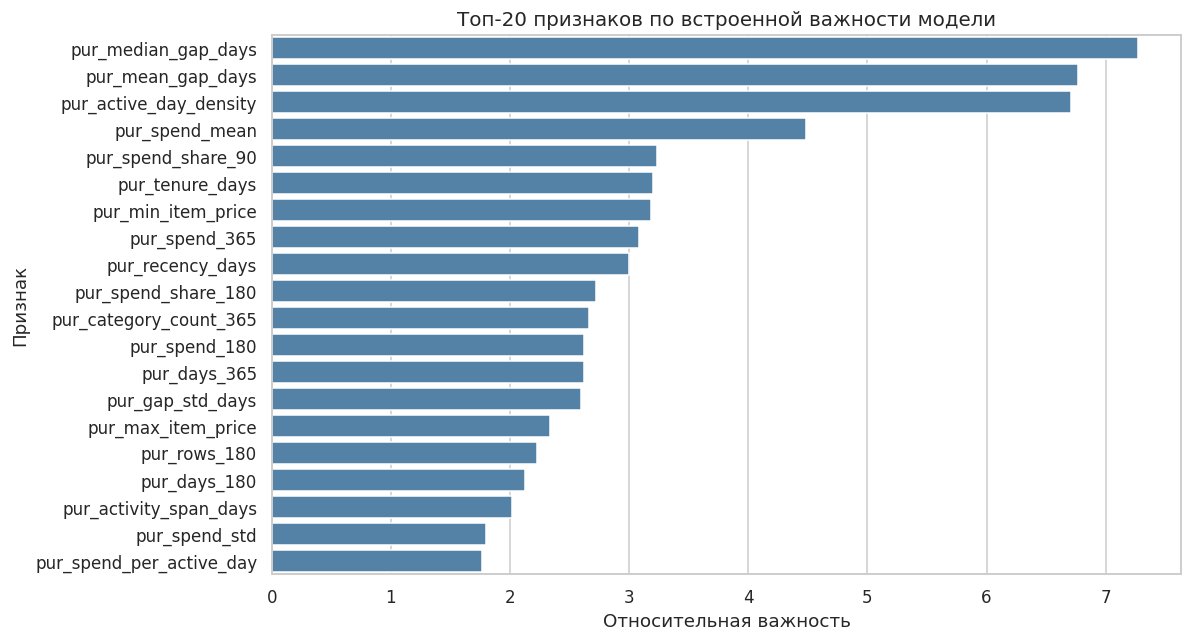

In [28]:
if hasattr(final_model,'feature_importances_'):
    imp = pd.Series(final_model.feature_importances_, index=X.columns).sort_values(ascending=False)
    top_imp = imp.head(20)
    display(top_imp.to_frame('importance'))
    fig, ax = plt.subplots(figsize=(11,6))
    sns.barplot(x=top_imp.values,y=top_imp.index,ax=ax, color="steelblue")
    ax.set(title='Топ-20 признаков по встроенной важности модели',xlabel='Относительная важность',ylabel='Признак')
    plt.tight_layout();plt.show()
else:
    print('У выбранного алгоритма нет встроенного feature_importances_; пропускаем график.')

**Вывод 5.3 — значимые признаки.** В проверенном прогоне в числе лидеров — **давность последнего клика**, **клики за 30/90/180 дней**, **частота реакции на рассылки**, **интервалы между покупками** и доля недавних трат. Важности бустинга **не показывают причинность**, а признаки коррелируют друг с другом. Для бизнеса разумно проверять качество на последующих временных срезах и, при необходимости, применять SHAP/Permutation Importance на отдельной валидации.

In [29]:
output_dir = Path('outputs')
output_dir.mkdir(exist_ok=True)
joblib.dump({'model':final_model, 'feature_names':X.columns.tolist(),
             'cutoff':str(cutoff.date()), 'threshold':threshold_optimal},
            output_dir / 'purchase_model.joblib')
with open(output_dir / 'metrics.json','w',encoding='utf-8') as f:
    json.dump({'winner':winner_name, 'cutoff':str(cutoff.date()),
               'validation_comparison': results.to_dict(orient='records'),
               'validation_threshold':threshold_optimal,
               'test':metrics_test},f,ensure_ascii=False,indent=2)
scored_test = pd.DataFrame({'client_id': features.loc[X_test.index, 'client_id'].values,
                            'purchase_probability': test_proba,
                            'actual_target':y_test.values})
scored_test.sort_values('purchase_probability',ascending=False).to_csv(
    output_dir/'test_client_scores.csv',index=False)
print('Файлы сохранены:', [str(p) for p in output_dir.iterdir()])

Файлы сохранены: ['outputs/purchase_model.joblib', 'outputs/metrics.json', 'outputs/test_client_scores.csv']


**Вывод 5.4 — артефакты.** Экспортированы обученная модель (`joblib`), перечень признаков и дата отсечения, таблица метрик (`metrics.json`) и список скоринга тестовых клиентов (`test_client_scores.csv`). При применении к новым клиентам необходимо формировать **точно те же признаки** на дату оценки; модель нельзя корректно запустить только на исходных шести полях покупок без этапа агрегации.

## 6. Общий итог и ограничения

**Итог:** задача бинарной классификации решена; лучшие варианты выбраны по валидационному ROC-AUC, тест открывался только после фиксации модели. В проверенном прогоне: **CatBoost (глубина 5), ROC-AUC теста ~0,778**. TOP-10% клиентов по скору охватывает около **44,4%** всех будущих покупателей теста. Это основа для приоритизации рекламных контактов.

**Ограничения:**
1. В ТЗ не указана точная дата построения `target`; февральский cutoff — логичный, но требующий подтверждения прокси из истории покупок. Если реальная дата иная, надо полностью перестроить окна и исключение будущих событий.
2. Один таргет на клиента не позволяет полноценную *out-of-time* проверку на последовательных целевых периодах. Stratified holdout оценивает переносимость **на других клиентов**, но не на будущие сезоны.
3. Повторяющиеся товарные строки не удаляются без ID позиции заказа. Пустые списки категорий трактуются как `unknown`.
4. Доля кликов/открытий — лишь прокси поведения, поскольку события относятся к разным каналам и могут повторяться для одного сообщения. Нельзя трактовать их как уникальный CTR.
5. На новых датах стоит проверить калибровку вероятностей, сезонный дрейф, бюджет кампаний и uplift/A/B-тест: высокая предсказанная склонность к покупке не означает, что реклама эту покупку вызовет.